# Experiment 04 — NequIP-L40S-MAE-batch1-9012782

Evaluate the saved **best NequIP model** against experiment 03's **SchNet with equal loss weights and learned offsets**, following `03-6thOctMeeting-adjustments.ipynb`.

This NequIP run used **six interaction layers, 128 channels per tensor type, rank 2, a 5.533 Å cutoff, batch size 1, energy MAE and force RMSE**. It is the original architecture, not the proposed smaller model. The history contains 11 completed validation epochs and part of a 12th training epoch; checkpoint metadata below identifies which epoch supplied the best model. The planned maximum was 300 epochs. The saved best weights, not the last weights, are evaluated.

**Benchmarks:** total-energy and per-atom-energy MAE/RMSE; force-component MAE/RMSE; energy/force parity plots; direct error comparisons; residual distributions; training-versus-validation loss histories. All accuracy results use the same **50 validation structures** as experiment 03. The held-out test set is not read. Validation selected these checkpoints, so these are not independent test-set estimates.

The models differ in architecture, training duration, batch size, learning rate and energy-loss definition. This is a comparison of the available trained models, not an isolated architecture experiment. **Compare energy/force errors separately, not the combined logged losses.** The same rule applies to interpreting overfitting curves.

Run with this project's `.venv` Python kernel from the project or its `experiments/` folder. The SchNet project is expected beside this project (override `SCHNET_PROJECT` if moved). Evaluation is sequential on CPU with four PyTorch threads. NMR and MD benchmarks were not part of notebook 03 and are not included here.


In [1]:
from pathlib import Path
from importlib.metadata import version
import gc
import hashlib
import json
import os
import platform
import time

import ase.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from IPython.display import display
from graph_pes.utils.calculator import GraphPESCalculator
from graph_pes.utils.nn import count_used_parameters

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'data/valid.xyz').is_file()
                and (p / 'graph-pes-results/NequIP-L40S-MAE-batch1-9012782').is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError('Start this notebook inside the NequIP_experiments project.')
SCHNET_PROJECT = Path(os.environ.get('SCHNET_PROJECT', str(PROJECT.parent / 'SchNET')))
STEM = '04-NequIP-L40S-MAE-batch1-9012782'
RUNS = {
    '03 · SchNet': SCHNET_PROJECT / 'graph-pes-results/lossratio_and_learnedOffsets-9004704',
    '04 · NequIP': PROJECT / 'graph-pes-results/NequIP-L40S-MAE-batch1-9012782',
}
labels = list(RUNS)
# An optional output override permits execution in a temporary working directory.
OUTPUT = Path(os.environ.get('NEQUIP_EVALUATION_OUTPUT', str(PROJECT / 'comparisons' / STEM)))
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
torch.set_default_dtype(torch.float32)
print('Project:', PROJECT)
print('graph-pes:', version('graph-pes'), '| PyTorch:', torch.__version__)
print('Device: CPU | threads:', torch.get_num_threads(), '| machine:', platform.machine())
for label, run in RUNS.items():
    assert (run / 'model.pt').is_file(), f'Missing saved model: {run}'


Project: /Users/louismcauliffe/code/research/NequIP_experiments
graph-pes: 1.0.2 | PyTorch: 2.6.0
Device: CPU | threads: 4 | machine: arm64


## 1. Verify saved models and training provenance

Read each saved training configuration and verify that its exported `model.pt` matches `checkpoints/best.ckpt`, including the non-tensor state. Checkpoints are trusted local files from these experiments. The NequIP run has no final `summary.yaml`; use checkpoint metadata and the separately cached W&B summary where available. Epochs are displayed starting at 1. Reaching the last batch of epoch 11 is not the same as a completed 300-epoch run.


In [2]:
def sha256(path):
    with open(path, 'rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def same_state(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_state(v, b[k]) for k, v in a.items())
    if isinstance(a, (tuple, list)):
        return type(a) is type(b) and len(a) == len(b) and all(same_state(x, y) for x, y in zip(a, b))
    return a == b

configs, checkpoint_metadata, metadata_rows = {}, {}, []
for label, run in RUNS.items():
    config = yaml.safe_load((run / 'train-config.yaml').read_text())
    configs[label] = config
    summary_path = run / 'summary.yaml'
    summary = yaml.safe_load(summary_path.read_text()) if summary_path.exists() else {}
    best = torch.load(run / 'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
    last = torch.load(run / 'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
    model = torch.load(run / 'model.pt', map_location='cpu', weights_only=False)
    state = {k.removeprefix('model.'): v for k, v in best['state_dict'].items() if k.startswith('model.')}
    assert same_state(state, model.state_dict()), f'{label}: exported model differs from best checkpoint'
    assert all(torch.isfinite(v).all().item() for v in state.values() if isinstance(v, torch.Tensor) and v.is_floating_point())
    model_name = 'nequip' if 'nequip' in config['model'] else 'schnet'
    arch = next(iter(config['model'][model_name].values()))
    best_epoch = int(best['epoch']) + 1
    last_epoch = int(last['epoch']) + 1
    checkpoint_metadata[label] = {
        'best_checkpoint_epoch': best_epoch, 'best_global_step': int(best['global_step']),
        'last_checkpoint_epoch': last_epoch, 'last_global_step': int(last['global_step']),
        'export_matches_best': True,
        'epoch_progress': last.get('loops', {}).get('fit_loop', {}).get('epoch_progress', {}),
    }
    energy_loss = config['loss']['energy']
    if isinstance(energy_loss, dict):
        energy_metric = next(iter(energy_loss.values())).get('metric', 'RMSE (default)')
    else:
        energy_metric = 'RMSE (default)'
    metadata_rows.append({
        'Model': label, 'Run': run.name, 'Best checkpoint epoch': best_epoch,
        'Last checkpoint epoch': last_epoch, 'Last global step': int(last['global_step']),
        'Planned max epochs': config['fitting']['trainer_kwargs']['max_epochs'],
        'Learnable parameters': count_used_parameters(model, only_learnable=True),
        'Layers': arch['layers'],
        'Features': arch.get('features', arch.get('channels', 'see saved config')),
        'Cutoff (Å)': arch['cutoff'],
        'Training batch size': config['fitting']['loader_kwargs']['batch_size'],
        'Energy loss': energy_metric, 'Initial LR': config['fitting']['optimizer']['lr'],
        'Seed': config['general']['seed'], 'Export matches best': True,
    })
    del model, state, best, last
    gc.collect()
run_metadata = pd.DataFrame(metadata_rows).set_index('Model')
display(run_metadata.drop(columns=['Features']).T)
run_metadata.to_csv(OUTPUT / 'run_metadata.csv')
print('Best checkpoint epochs:', {k: v['best_checkpoint_epoch'] for k, v in checkpoint_metadata.items()})
print('Combined training losses are not a shared accuracy metric across these runs.')


Best checkpoint epochs: {'03 · SchNet': 244, '04 · NequIP': 9}
Combined training losses are not a shared accuracy metric across these runs.


Model,03 · SchNet,04 · NequIP
Run,lossratio_and_learnedOffsets-9004704,NequIP-L40S-MAE-batch1-9012782
Best checkpoint epoch,244,9
Last checkpoint epoch,300,11
Last global step,60000,8800
Planned max epochs,300,300
Learnable parameters,61786,6449280
Layers,3,6
Cutoff (Å),5.0,5.533
Training batch size,4,1
Energy loss,RMSE (default),MAE


## 2. Load the identical validation split

Verify SHA-256 equality of the SchNet and NequIP training and validation files before comparing models. The 150 held-out test structures remain untouched. References retain the precision stored in the XYZ files; prediction errors are accumulated in NumPy float64, as in notebook 03.


In [3]:
split_hashes = {}
for split in ['train', 'valid']:
    here, baseline = PROJECT / f'data/{split}.xyz', SCHNET_PROJECT / f'data/{split}.xyz'
    assert sha256(here) == sha256(baseline), f'Different {split} data between projects'
    split_hashes[split] = sha256(here)
VALID_PATH = PROJECT / "data/valid.xyz"
validation = ase.io.read(VALID_PATH, index=":")
assert len(validation) > 0
n_atoms = np.array([len(atoms) for atoms in validation], dtype=int)
reference_energy = np.array([float(atoms.info["QM_energy"]) for atoms in validation])
reference_forces = np.concatenate([
    np.asarray(atoms.arrays["QM_forces"], dtype=float) for atoms in validation
])
atom_offsets = np.concatenate(([0], np.cumsum(n_atoms)))
print(f"Validation: {len(validation)} structures, {n_atoms.sum():,} atoms, "
      f"{reference_forces.size:,} force components")
assert len(validation) == 50
assert np.isfinite(reference_energy).all() and np.isfinite(reference_forces).all()
print('Training and validation files match SchNet exactly.')


Validation: 50 structures, 7,200 atoms, 21,600 force components
Training and validation files match SchNet exactly.


## 3. Recalculate energy and force predictions on CPU

Use the same ASE/Graph-PES evaluation path for both models, one structure at a time. Request energy and forces together to avoid a redundant energy-only forward pass. Freeze weight gradients for evaluation while retaining position gradients needed to obtain forces. Do **not** use `torch.no_grad()` or inference mode around force prediction.

Warm up on the first validation structure once per model, then time all 50 structures. These timings include neighbour-list construction and Python bookkeeping, exclude model loading and warm-up, and are descriptive local timings rather than repeated performance measurements. Save each model's predictions immediately after its evaluation so later plotting does not require more inference.


In [4]:
def evaluate_model(run_directory, structures):
    model = torch.load(run_directory / 'model.pt', map_location='cpu', weights_only=False)
    model.eval().requires_grad_(False)
    calculator = GraphPESCalculator(model, device='cpu', skin=0)
    start_warmup = time.perf_counter()
    with torch.enable_grad():
        calculator.calculate(structures[0].copy(), properties=['energy', 'forces'])
    warmup_seconds = time.perf_counter() - start_warmup
    print(f'{run_directory.name}: warm-up {warmup_seconds:.2f} s', flush=True)
    energies, forces, rows = [], [], []
    started = time.perf_counter()
    for i, structure in enumerate(structures):
        step_started = time.perf_counter()
        with torch.enable_grad():
            calculator.calculate(structure.copy(), properties=['energy', 'forces'])
        predicted_e = float(calculator.results['energy'])
        predicted_f = np.asarray(calculator.results['forces'], dtype=float).copy()
        step_seconds = time.perf_counter() - step_started
        reference_e = float(structure.info['QM_energy'])
        reference_f = np.asarray(structure.arrays['QM_forces'], dtype=float)
        assert predicted_f.shape == reference_f.shape == (len(structure), 3)
        assert np.isfinite(predicted_e) and np.isfinite(predicted_f).all(), f'Nonfinite prediction on structure {i}'
        e_error, f_error = predicted_e - reference_e, predicted_f - reference_f
        energies.append(predicted_e)
        forces.append(predicted_f)
        rows.append({
            'structure_index': i, 'n_atoms': len(structure),
            'reference_energy_eV': reference_e, 'predicted_energy_eV': predicted_e,
            'reference_energy_per_atom_eV': reference_e / len(structure),
            'predicted_energy_per_atom_eV': predicted_e / len(structure),
            'energy_error_meV_per_atom': 1000 * e_error / len(structure),
            'force_MAE_eV_per_A': np.abs(f_error).mean(),
            'force_RMSE_eV_per_A': np.sqrt(np.mean(f_error**2)),
            'energy_and_forces_seconds': step_seconds,
        })
        if (i + 1) % 5 == 0 or i + 1 == len(structures):
            print(f'{run_directory.name}: {i + 1}/{len(structures)} ({time.perf_counter() - started:.1f} s)', flush=True)
    result = {
        'energy': np.asarray(energies), 'forces': np.concatenate(forces),
        'structures': pd.DataFrame(rows), 'evaluation_seconds': time.perf_counter() - started,
        'warmup_seconds': warmup_seconds,
    }
    destination = OUTPUT / 'predictions' / run_directory.name
    destination.mkdir(parents=True, exist_ok=True)
    result['structures'].to_csv(destination / 'predictions.csv', index=False)
    np.savez_compressed(destination / 'forces.npz', n_atoms=n_atoms, atom_offsets=atom_offsets,
                        reference=reference_forces, predicted=result['forces'])
    del calculator, model
    gc.collect()
    return result

results = {}
for label, run in RUNS.items():
    results[label] = evaluate_model(run, validation)
print('Both models evaluated. Later cells reuse these predictions.')


lossratio_and_learnedOffsets-9004704: warm-up 0.04 s
lossratio_and_learnedOffsets-9004704: 5/50 (0.0 s)
lossratio_and_learnedOffsets-9004704: 10/50 (0.1 s)
lossratio_and_learnedOffsets-9004704: 15/50 (0.1 s)
lossratio_and_learnedOffsets-9004704: 20/50 (0.2 s)
lossratio_and_learnedOffsets-9004704: 25/50 (0.2 s)
lossratio_and_learnedOffsets-9004704: 30/50 (0.2 s)
lossratio_and_learnedOffsets-9004704: 35/50 (0.3 s)
lossratio_and_learnedOffsets-9004704: 40/50 (0.3 s)
lossratio_and_learnedOffsets-9004704: 45/50 (0.4 s)
lossratio_and_learnedOffsets-9004704: 50/50 (0.4 s)
NequIP-L40S-MAE-batch1-9012782: warm-up 6.98 s
NequIP-L40S-MAE-batch1-9012782: 5/50 (32.1 s)
NequIP-L40S-MAE-batch1-9012782: 10/50 (66.2 s)
NequIP-L40S-MAE-batch1-9012782: 15/50 (98.9 s)
NequIP-L40S-MAE-batch1-9012782: 20/50 (127.5 s)
NequIP-L40S-MAE-batch1-9012782: 25/50 (160.5 s)
NequIP-L40S-MAE-batch1-9012782: 30/50 (190.1 s)
NequIP-L40S-MAE-batch1-9012782: 35/50 (219.0 s)
NequIP-L40S-MAE-batch1-9012782: 40/50 (250.1 s)
N

## 4. Aggregate metrics and direct comparison

In [5]:
def error_metrics(errors):
    errors = np.asarray(errors, dtype=np.float64)
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))
    assert rmse + 1e-12 >= mae
    return float(mae), float(rmse)

metric_rows = []
for label, result in results.items():
    total_errors = result["energy"] - reference_energy
    epa_errors = total_errors / n_atoms
    force_errors = result["forces"] - reference_forces
    result["energy_errors_meV_per_atom"] = 1000 * epa_errors
    result["force_errors"] = force_errors
    for quantity, errors, units in [
        ("Total energy", total_errors, "eV"),
        ("Energy per atom", 1000 * epa_errors, "meV/atom"),
        ("Force components", force_errors, "eV/Å"),
    ]:
        mae, rmse = error_metrics(errors)
        metric_rows.append({"Model": label, "Quantity": quantity, "Units": units,
                            "MAE": mae, "RMSE": rmse})

metrics = pd.DataFrame(metric_rows).set_index(["Model", "Quantity"])
display(metrics.round(6))

comparison = pd.DataFrame(index=labels)
for quantity, units in [("Energy per atom", "meV/atom"), ("Force components", "eV/Å")]:
    for metric in ["MAE", "RMSE"]:
        comparison[f"{quantity} {metric} ({units})"] = [
            metrics.loc[(label, quantity), metric] for label in labels
        ]
comparison.index.name = "Model"
display(comparison.round(6))

difference = (comparison.loc["04 · NequIP"] - comparison.loc["03 · SchNet"]).to_frame(
    "04 − 03 (negative = improvement)"
)
display(difference.round(6))
relative_change = (100 * (comparison.loc[labels[1]] / comparison.loc[labels[0]] - 1)).to_frame('NequIP change vs SchNet (%)')
display(relative_change.round(2))
timings = pd.DataFrame({label: {
    'Warm-up (s)': r['warmup_seconds'], '50-structure evaluation (s)': r['evaluation_seconds'],
    'Mean energy+force call (s)': r['structures']['energy_and_forces_seconds'].mean(),
    'Median energy+force call (s)': r['structures']['energy_and_forces_seconds'].median(),
} for label, r in results.items()}).T
display(timings.round(3))


Units       MAE       RMSE
Model       Quantity                                       
03 · SchNet Total energy            eV  0.406253   0.504389
            Energy per atom   meV/atom  2.821202   3.502702
            Force components      eV/Å  0.120912   0.179777
04 · NequIP Total energy            eV  1.401002   1.502913
            Energy per atom   meV/atom  9.729178  10.436893
            Force components      eV/Å  0.043693   0.084879

,Energy per atom MAE (meV/atom),Energy per atom RMSE (meV/atom),Force components MAE (eV/Å),Force components RMSE (eV/Å)
Model,,,,
03 · SchNet,2.821202,3.502702,0.120912,0.179777
04 · NequIP,9.729178,10.436893,0.043693,0.084879


,04 − 03 (negative = improvement)
Energy per atom MAE (meV/atom),6.907975
Energy per atom RMSE (meV/atom),6.934191
Force components MAE (eV/Å),-0.077219
Force components RMSE (eV/Å),-0.094898


,NequIP change vs SchNet (%)
Energy per atom MAE (meV/atom),244.86
Energy per atom RMSE (meV/atom),197.97
Force components MAE (eV/Å),-63.86
Force components RMSE (eV/Å),-52.79


,Warm-up (s),50-structure evaluation (s),Mean energy+force call (s),Median energy+force call (s)
03 · SchNet,0.035,0.411,0.008,0.008
04 · NequIP,6.979,316.555,6.331,6.285


## 5. Energy and force parity plots

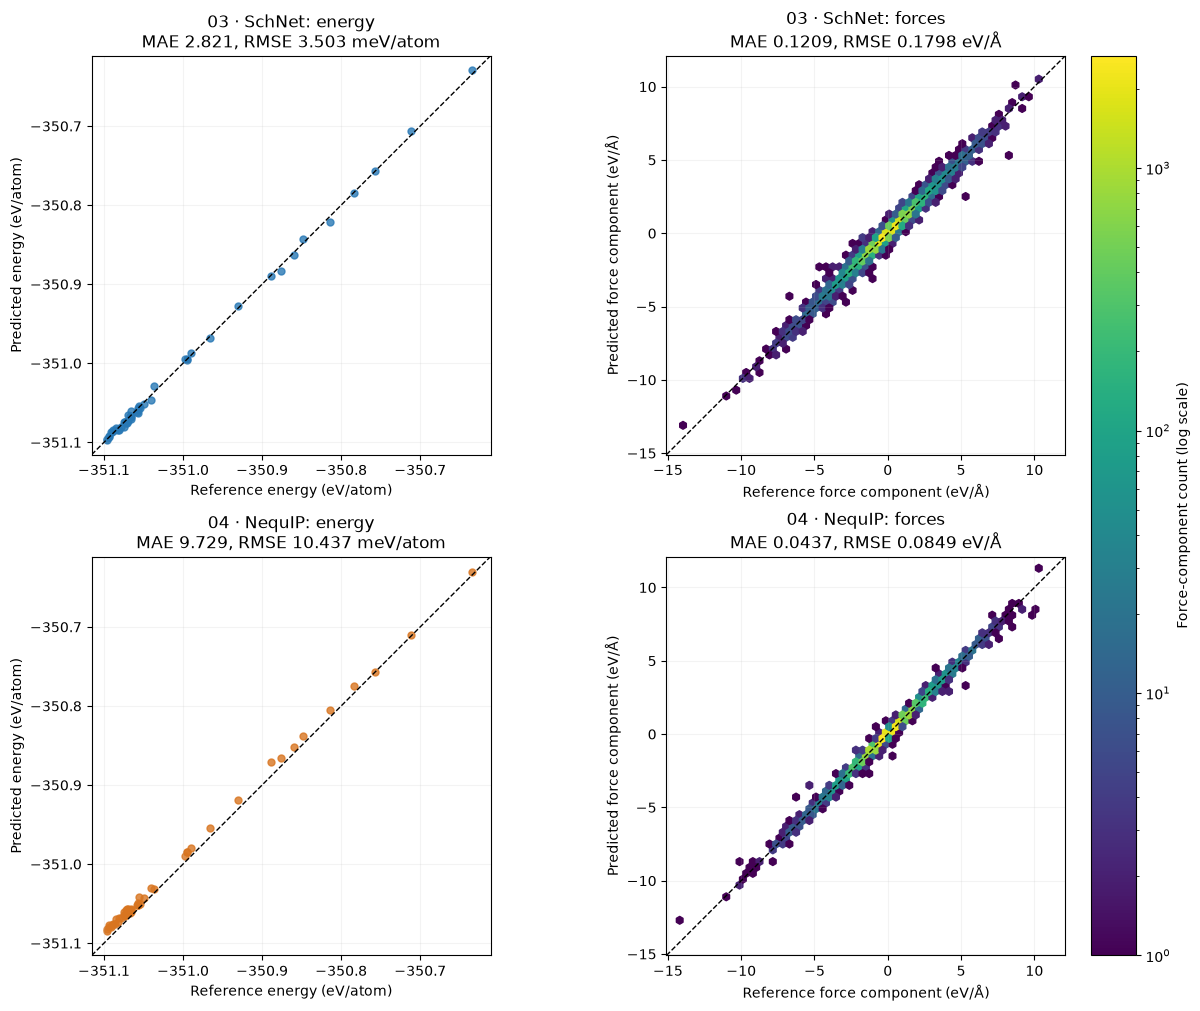

In [6]:
from matplotlib.colors import LogNorm

colours = {"03 · SchNet": "#2878B5", "04 · NequIP": "#D87520"}

def padded_limits(arrays):
    low = min(float(np.min(a)) for a in arrays)
    high = max(float(np.max(a)) for a in arrays)
    margin = 0.04 * (high - low) if high > low else 0.01
    return low - margin, high + margin

ref_epa = reference_energy / n_atoms
energy_limits = padded_limits([ref_epa] + [r["energy"] / n_atoms for r in results.values()])
force_limits = padded_limits([reference_forces] + [r["forces"] for r in results.values()])
force_norm = LogNorm(vmin=1, vmax=max(2, reference_forces.size))

fig_parity, axes = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
hexplots = []
for row, (label, result) in enumerate(results.items()):
    ax = axes[row, 0]
    ax.scatter(ref_epa, result["energy"] / n_atoms, s=25, alpha=0.8, color=colours[label])
    em = metrics.loc[(label, "Energy per atom")]
    ax.set_title(f"{label}: energy\nMAE {em['MAE']:.3f}, RMSE {em['RMSE']:.3f} meV/atom")
    ax.set_xlabel("Reference energy (eV/atom)")
    ax.set_ylabel("Predicted energy (eV/atom)")
    ax.ticklabel_format(useOffset=False, style="plain")

    ax = axes[row, 1]
    hexplots.append(ax.hexbin(
        reference_forces.ravel(), result["forces"].ravel(),
        gridsize=60, extent=(*force_limits, *force_limits),
        mincnt=1, norm=force_norm, cmap="viridis",
    ))
    fm = metrics.loc[(label, "Force components")]
    ax.set_title(f"{label}: forces\nMAE {fm['MAE']:.4f}, RMSE {fm['RMSE']:.4f} eV/Å")
    ax.set_xlabel("Reference force component (eV/Å)")
    ax.set_ylabel("Predicted force component (eV/Å)")

    for col, limits in enumerate([energy_limits, force_limits]):
        ax = axes[row, col]
        ax.plot(limits, limits, "k--", lw=1)
        ax.set(xlim=limits, ylim=limits)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.15)

# Use the largest observed bin count for a shared, readable colour range.
force_norm.vmax = max(2, *(float(h.get_array().max()) for h in hexplots))
fig_parity.colorbar(hexplots[0], ax=list(axes[:, 1]), label="Force-component count (log scale)")
plt.show()


## 6. Compare errors directly

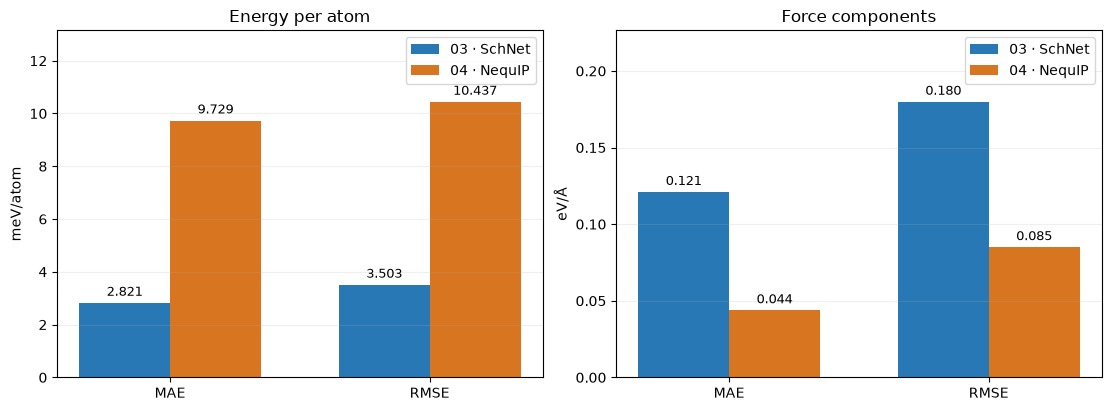

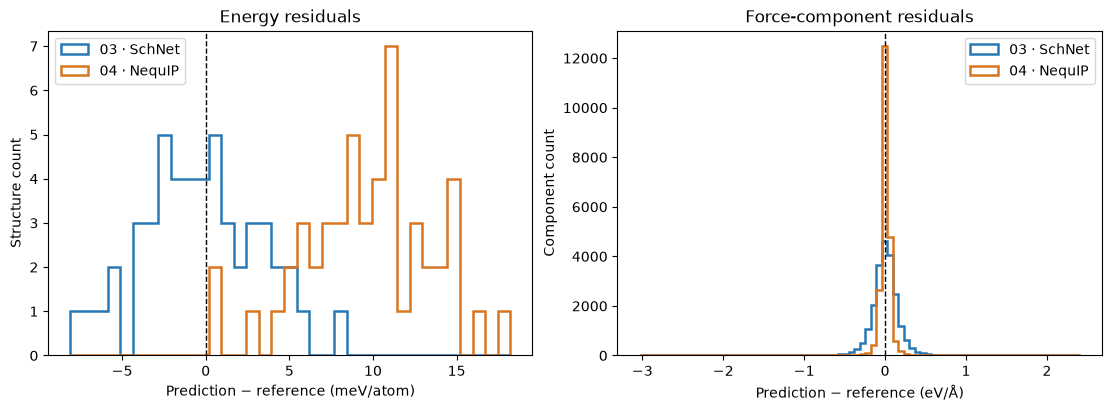

In [7]:
fig_metrics, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
x = np.arange(2)
width = 0.35
for ax, quantity, units in zip(axes, ["Energy per atom", "Force components"], ["meV/atom", "eV/Å"]):
    for j, label in enumerate(labels):
        values = [metrics.loc[(label, quantity), m] for m in ["MAE", "RMSE"]]
        bars = ax.bar(x + (j - 0.5) * width, values, width, label=label, color=colours[label])
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_xticks(x, ["MAE", "RMSE"])
    ax.set_title(quantity)
    ax.set_ylabel(units)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
plt.show()

fig_errors, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, key, units, title in [
    (axes[0], "energy_errors_meV_per_atom", "meV/atom", "Energy residuals"),
    (axes[1], "force_errors", "eV/Å", "Force-component residuals"),
]:
    combined = np.concatenate([r[key].ravel() for r in results.values()])
    bins = np.histogram_bin_edges(combined, bins=35 if ax is axes[0] else 80)
    for label, result in results.items():
        ax.hist(result[key].ravel(), bins=bins, histtype="step", linewidth=1.8,
                color=colours[label], label=label)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(f"Prediction − reference ({units})")
    ax.set_ylabel("Structure count" if ax is axes[0] else "Component count")
    ax.legend()
plt.show()


## 7. Save predictions, metrics and comparison figures

In [8]:
for label, run in RUNS.items():
    destination = OUTPUT / 'predictions' / run.name
    metrics.loc[label].to_csv(destination / 'metrics.csv')
metrics.to_csv(OUTPUT / 'validation_metrics.csv')
comparison.to_csv(OUTPUT / 'validation_comparison.csv')
difference.to_csv(OUTPUT / '04_minus_03.csv')
relative_change.to_csv(OUTPUT / 'relative_change_percent.csv')
timings.to_csv(OUTPUT / 'local_cpu_timings.csv')
for name, figure in [('parity', fig_parity), ('metrics', fig_metrics), ('residuals', fig_errors)]:
    figure.savefig(OUTPUT / f'{name}.png', dpi=180, bbox_inches='tight')

manifest = {
    'split': 'validation', 'data_path': 'data/valid.xyz', 'data_sha256': sha256(VALID_PATH),
    'matching_split_hashes': split_hashes, 'n_structures': len(validation),
    'device': 'cpu', 'torch_threads': torch.get_num_threads(), 'machine': platform.machine(),
    'graph_pes_version': version('graph-pes'), 'torch_version': torch.__version__,
    'energy_units': 'eV; per-atom metrics displayed in meV/atom', 'force_units': 'eV/Å',
    'timing_protocol': 'One warm-up; then 50 sequential joint energy/force calls, skin=0, frozen weights, position gradients enabled. Excludes model load.',
    'test_set_read': False,
    'runs': {label: {
        'run': run.name, 'model_sha256': sha256(run / 'model.pt'),
        'config_sha256': sha256(run / 'train-config.yaml'),
        'best_checkpoint_sha256': sha256(run / 'checkpoints/best.ckpt'),
        **checkpoint_metadata[label], 'evaluation_seconds': results[label]['evaluation_seconds'],
    } for label, run in RUNS.items()},
}
(OUTPUT / 'evaluation_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Saved predictions, metrics, figures and provenance for', STEM)


Saved predictions, metrics, figures and provenance for 04-NequIP-L40S-MAE-batch1-9012782


## 8. Training versus validation histories

Follow notebook 03's diagnostic using full, unsampled W&B history cached locally for offline reuse. Only existing runs are read; no W&B training run is created. Training curves are means of **logged batches**, not a fresh evaluation of the training set. Validation curves use the last logged validation loss per epoch. Show both the whole run and its final ten epochs, so the partial NequIP run is visible rather than applying experiment 03's fixed epoch-26 cutoff.

Loss definitions differ, so use separate axes and interpret trends within each model. A gap alone does not establish overfitting; 11 epochs do not establish convergence. Nonfinite values, if present, are reported rather than plotted as zeros. NequIP has 11 validation epochs and a partially logged 12th training epoch. Cross markers identify that partial training epoch; its mean is not a complete-epoch estimate.


In [9]:
history_dir = OUTPUT / 'loss-history'
history_dir.mkdir(parents=True, exist_ok=True)
REFRESH_HISTORY = False
loss_histories = {}
api = None
for label, run_directory in RUNS.items():
    run_id = run_directory.name
    cache = history_dir / f'{run_id}.csv'
    old_cache = SCHNET_PROJECT / 'comparisons/03-6thOctMeeting-adjustments/loss-history' / f'{run_id}.csv'
    if not cache.exists() and old_cache.exists() and not REFRESH_HISTORY:
        cache.write_bytes(old_cache.read_bytes())
    if cache.exists() and not REFRESH_HISTORY:
        history = pd.read_csv(cache)
    else:
        import wandb
        if api is None:
            api = wandb.Api(timeout=30)
        wb = configs[label]['wandb']
        run = api.run(f"{wb['entity']}/{wb['project']}/{run_id}")
        records = []
        for split in ['train', 'valid']:
            key = f'{split}/loss/total'
            for row in run.scan_history(keys=['epoch', key], page_size=1000):
                if row.get(key) is not None and row.get('epoch') is not None:
                    records.append({'epoch': row['epoch'], 'split': split, 'loss': row[key]})
        history = pd.DataFrame(records, columns=['epoch', 'split', 'loss'])
        history.to_csv(cache, index=False)
    assert not history.empty and set(history['split']) == {'train', 'valid'}
    history[['epoch', 'loss']] = history[['epoch', 'loss']].apply(pd.to_numeric)
    finite = np.isfinite(history[['epoch', 'loss']].to_numpy()).all(axis=1)
    print(f'{label}: {len(history):,} records; {(~finite).sum()} nonfinite records')
    loss_histories[label] = history.loc[finite].copy()


03 · SchNet: 6,300 records; 0 nonfinite records
04 · NequIP: 930 records; 0 nonfinite records


A short partial run does not establish convergence or rule out later overfitting.


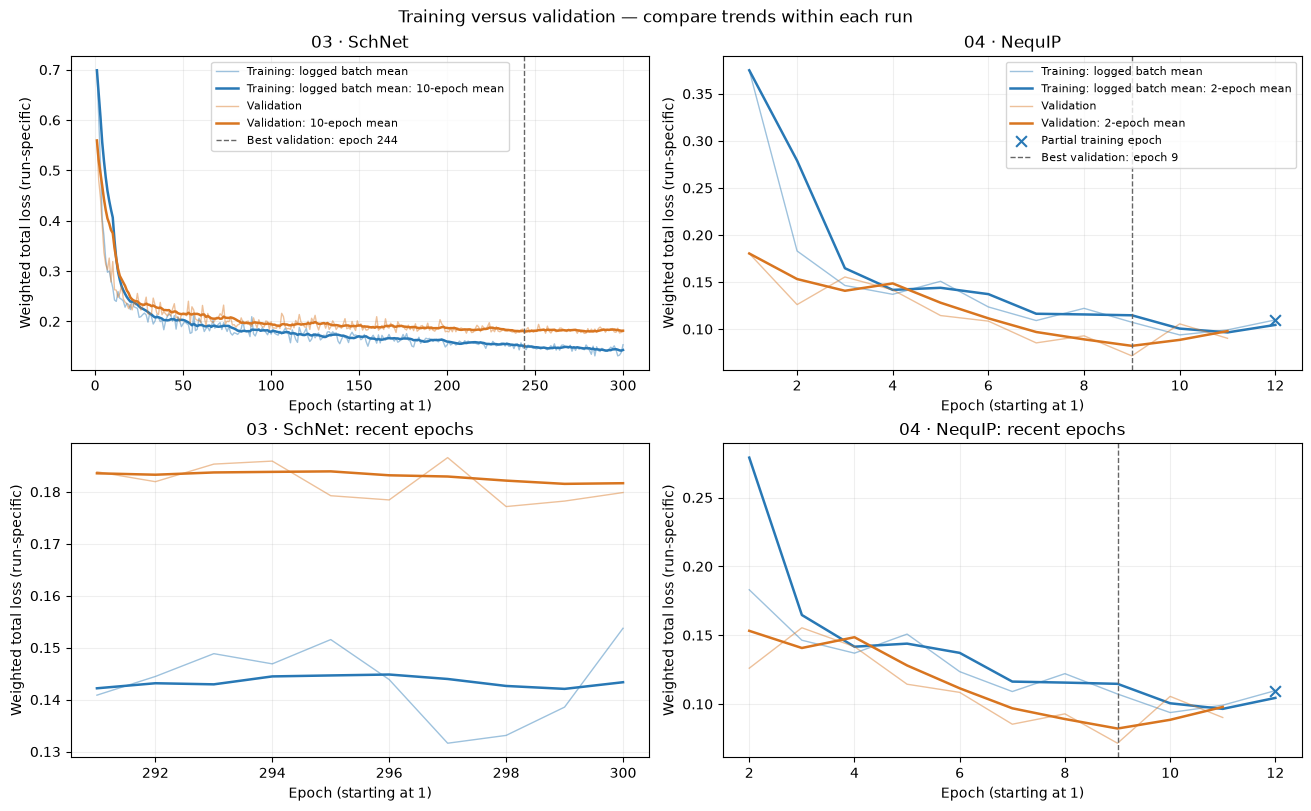

,Validation epochs logged,Best epoch,Best validation loss,Final validation loss,Training mean at last validation,Latest training epoch logged,Partial training epoch present
Model,,,,,,,
03 · SchNet,300,244,0.175987,0.179856,0.153739,300,False
04 · NequIP,11,9,0.071544,0.090219,0.099160,12,True


In [10]:
fig_losses, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
loss_trend_rows = []
for column, (label, history) in enumerate(loss_histories.items()):
    train_curve = history[history['split'].eq('train')].groupby('epoch')['loss'].mean().sort_index()
    valid_curve = history[history['split'].eq('valid')].groupby('epoch')['loss'].last().sort_index()
    best_epoch = valid_curve.idxmin()
    window = min(10, max(1, len(valid_curve) // 5))
    last_start = max(0, int(valid_curve.index.max()) - 9)
    for row, ax in enumerate(axes[:, column]):
        for curve, name, colour in [(train_curve, 'Training: logged batch mean', '#2878B5'),
                                    (valid_curve, 'Validation', '#D87520')]:
            visible = curve if row == 0 else curve[curve.index >= last_start]
            ax.plot(visible.index + 1, visible, color=colour, alpha=0.45, linewidth=1, label=name)
            if window > 1:
                smooth = curve.rolling(window, min_periods=1).mean()
                smooth = smooth if row == 0 else smooth[smooth.index >= last_start]
                ax.plot(smooth.index + 1, smooth, color=colour, linewidth=1.8,
                        label=f'{name}: {window}-epoch mean')
        partial = train_curve[train_curve.index > valid_curve.index.max()]
        if not partial.empty:
            ax.scatter(partial.index + 1, partial.values, marker='x', s=60, color='#2878B5',
                       label='Partial training epoch', zorder=5)
        if row == 0 or best_epoch >= last_start:
            ax.axvline(best_epoch + 1, color='#666666', linestyle='--', linewidth=1,
                       label=f'Best validation: epoch {int(best_epoch) + 1}')
        ax.grid(alpha=0.2)
        ax.set_xlabel('Epoch (starting at 1)')
        ax.set_ylabel('Weighted total loss (run-specific)')
        ax.set_title(label if row == 0 else f'{label}: recent epochs')
        if row == 0:
            ax.legend(fontsize=8)
    loss_trend_rows.append({'Model': label, 'Validation epochs logged': len(valid_curve),
                           'Best epoch': int(best_epoch) + 1, 'Best validation loss': valid_curve.min(),
                           'Final validation loss': valid_curve.iloc[-1],
                           'Training mean at last validation': train_curve.loc[train_curve.index <= valid_curve.index.max()].iloc[-1],
                           'Latest training epoch logged': int(train_curve.index.max()) + 1,
                           'Partial training epoch present': bool(train_curve.index.max() > valid_curve.index.max())})
fig_losses.suptitle('Training versus validation — compare trends within each run')
plt.show()
loss_trends = pd.DataFrame(loss_trend_rows).set_index('Model')
display(loss_trends.round(6))
loss_trends.to_csv(history_dir / 'training_trends.csv')
for extension in ['png']:
    fig_losses.savefig(history_dir / f'training_vs_validation.{extension}', dpi=180)
print('A short partial run does not establish convergence or rule out later overfitting.')


## 9. Interpretation

The table below states the measured validation changes, with negative percentages indicating lower error. The selected models used different losses and training budgets, so improvement is evidence about these checkpoints, not a controlled claim about architecture alone. CPU timings are for this machine and this evaluation path; do not extrapolate them to training or long MD trajectories.

**Observed result:** NequIP reduces force-component MAE by 63.9% and RMSE by 52.8%, but energy-per-atom MAE rises from 2.82 to 9.73 meV/atom. Its energy residuals are all positive (mean +9.73 meV/atom), suggesting a systematic energy bias worth investigating; no offset correction has been fitted to validation data. These results use the best checkpoint from epoch 9.

The six-layer, 128-channel NequIP model ran successfully on the local Apple M3 CPU: 50 energy-and-force evaluations took 316.6 seconds after warm-up (mean 6.33 seconds per structure). This is useful for small offline evaluations but does not establish practical speed for long MD runs.


In [11]:
display(comparison.round(6))
for quantity in ['Energy per atom', 'Force components']:
    for metric in ['MAE', 'RMSE']:
        old = metrics.loc[(labels[0], quantity), metric]
        new = metrics.loc[(labels[1], quantity), metric]
        change = 100 * (new / old - 1)
        print(f'{quantity} {metric}: {change:+.1f}% vs SchNet')
print(f"NequIP checkpoint: epoch {checkpoint_metadata[labels[1]]['best_checkpoint_epoch']}; last saved epoch {checkpoint_metadata[labels[1]]['last_checkpoint_epoch']}.")
print('All 50 validation structures evaluated; held-out test data were not used.')


Energy per atom MAE: +244.9% vs SchNet
Energy per atom RMSE: +198.0% vs SchNet
Force components MAE: -63.9% vs SchNet
Force components RMSE: -52.8% vs SchNet
NequIP checkpoint: epoch 9; last saved epoch 11.
All 50 validation structures evaluated; held-out test data were not used.


,Energy per atom MAE (meV/atom),Energy per atom RMSE (meV/atom),Force components MAE (eV/Å),Force components RMSE (eV/Å)
Model,,,,
03 · SchNet,2.821202,3.502702,0.120912,0.179777
04 · NequIP,9.729178,10.436893,0.043693,0.084879
